# DNA hybridisation

The hybridised fraction of DNA is given by:
$$
\theta(T) = \frac{Z_{pt}}{Z_{p}+Z_{pt}} = \frac{c_t(T)e^{-\beta \Delta G}}{1+c_t(T)e^{-\beta\Delta G} }
$$
Where the temperature dependent concentration $c_t(T)= \frac{N\lambda^3_T}{V}$ and the thermal wavelength:
$$
\lambda_T = \sqrt{\frac{2\pi\hbar^2}{mk_B T}}
$$


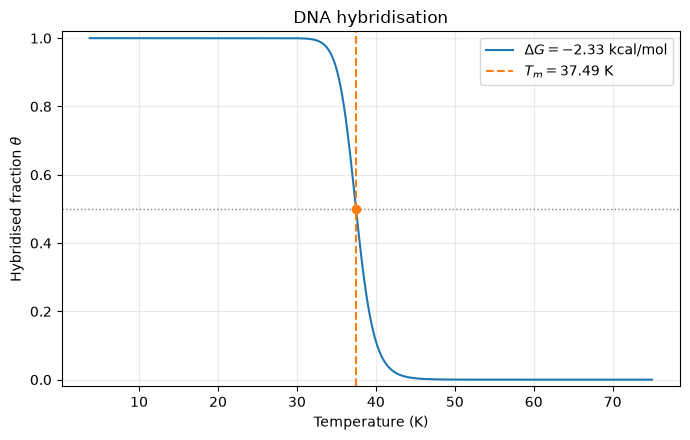

Model parameters: 1e-06 M target concentration, 6600 g/mol strand molar mass
Melting temperature at -2.33 kcal/mol: 37.49 K


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import Avogadro, Boltzmann, hbar
from scipy.optimize import brentq
from scipy.special import expit

# Editable model parameters. Mass and concentration are illustrative defaults.
delta_G_kcal_mol = -2.33
strand_molar_mass_g_mol = 6600.0  # Approximate mass of a 20-nucleotide strand.
target_concentration_M = 1e-6    # 1 micromolar; mol/L.

mass = strand_molar_mass_g_mol * 1e-3 / Avogadro  # kg per strand
number_density = target_concentration_M * 1e3 * Avogadro  # strands/m^3
kcal_mol_to_J_per_molecule = 4184.0 / Avogadro


def log_binding_weight(T, delta_G):
    """log(c_t exp(-beta Delta G)); T in K, delta_G in kcal/mol."""
    T = np.asarray(T, dtype=float)
    if np.any(T <= 0):
        raise ValueError("Temperature must be positive (K).")
    log_c_t = (np.log(number_density)
               + 1.5 * (np.log(2 * np.pi * hbar**2 / (mass * Boltzmann))
                        - np.log(T)))
    return log_c_t - delta_G * kcal_mol_to_J_per_molecule / (Boltzmann * T)


def hybridised_fraction(T, delta_G):
    # The logistic form avoids overflow at low temperatures.
    return expit(log_binding_weight(T, delta_G))


def melting_temperature(delta_G):
    """Solve theta(T_m) = 1/2 for favourable (negative) Delta G."""
    if delta_G >= 0:
        raise ValueError("This melting curve requires negative Delta G.")
    upper_T = 1.0
    while log_binding_weight(upper_T, delta_G) > 0:
        upper_T *= 2
    return brentq(lambda T: log_binding_weight(T, delta_G),
                  1e-12, upper_T, xtol=1e-12)


T_m = melting_temperature(delta_G_kcal_mol)
temperatures = np.linspace(0.1 * T_m, 2.0 * T_m, 800)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(temperatures, hybridised_fraction(temperatures, delta_G_kcal_mol),
        label=rf"$\Delta G = {delta_G_kcal_mol:.2f}$ kcal/mol")
ax.axhline(0.5, color="grey", linestyle=":", linewidth=1)
ax.axvline(T_m, color="tab:orange", linestyle="--",
           label=rf"$T_m = {T_m:.2f}$ K")
ax.scatter([T_m], [0.5], color="tab:orange", zorder=3)
ax.set(xlabel="Temperature (K)", ylabel=r"Hybridised fraction $\theta$",
       title="DNA hybridisation", ylim=(-0.02, 1.02))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

print(f"Model parameters: {target_concentration_M:g} M target concentration, "
      f"{strand_molar_mass_g_mol:g} g/mol strand molar mass")
print(f"Melting temperature at {delta_G_kcal_mol:.2f} kcal/mol: {T_m:.2f} K")


The melting temperature of DNA is defined as the temperature at which the hybridised fraction is half.
$$
\theta(T_m)=\frac{1}{2}
$$
The melting temperature satisfies the following implicit equation, which we solve numerically. Here $\Delta G$ is the free energy per molecule (converted from kcal/mol in the code).

$$
T_m = \frac{2\pi\hbar^2}{m k_B}\left(\frac{N}{V}\right)^{2/3}\exp\left(-\frac{2\Delta G}{3k_BT_m}\right)
$$

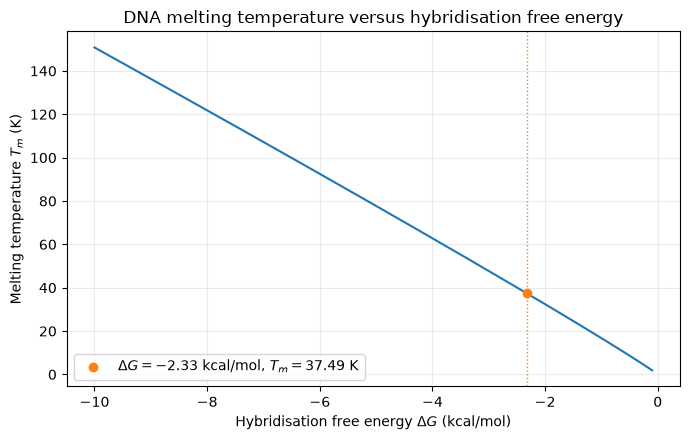

In [2]:
# Keep the same strand mass and concentration as in the first code cell.
# Include the chosen hybridisation free energy in the plotted range.
delta_G_values = np.linspace(min(-10.0, 2 * delta_G_kcal_mol), -0.1, 300)
melting_temperatures = np.array([melting_temperature(g) for g in delta_G_values])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(delta_G_values, melting_temperatures)
ax.scatter([delta_G_kcal_mol], [T_m], color="tab:orange", zorder=3,
           label=rf"$\Delta G = {delta_G_kcal_mol:.2f}$ kcal/mol, $T_m = {T_m:.2f}$ K")
ax.axvline(delta_G_kcal_mol, color="tab:orange", linestyle=":", linewidth=1)
ax.set(xlabel=r"Hybridisation free energy $\Delta G$ (kcal/mol)",
       ylabel=r"Melting temperature $T_m$ (K)",
       title="DNA melting temperature versus hybridisation free energy")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
